# Delhivery – Feature Engineering Case Study
## 1. Problem Statement
Delhivery's data pipelines emit one row per **segment** of a trip (think connecting flights). To let the data-science team build forecasting models (e.g. delivery time), we must:
1. Clean the raw data and understand its structure.
2. Merge segment rows into **trip-level** records using sensible aggregations.
3. Engineer features (location, time, duration).
4. Compare actual vs OSRM (planned) time/distance and segment vs total fields.
5. Treat outliers, encode categoricals and scale numeric columns.
6. Convert findings into simple business insights and recommendations.

**Additional views:** how far is real performance from OSRM's estimate (a proxy for delay/inefficiency), which corridors carry the most volume, and which states/routes are the slowest relative to plan.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.preprocessing import MinMaxScaler
import warnings; warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi']=90
df = pd.read_csv('delhivery_data.csv')
df.head()

,data,trip_creation_time,route_schedule_uuid,route_type,trip_uuid,source_center,source_name,destination_center,destination_name,od_start_time,...,cutoff_timestamp,actual_distance_to_destination,actual_time,osrm_time,osrm_distance,factor,segment_actual_time,segment_osrm_time,segment_osrm_distance,segment_factor
0,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,2018-09-20 04:27:55,10.435660,14.0,11.0,11.9653,1.272727,14.0,11.0,11.9653,1.272727
1,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,2018-09-20 04:17:55,18.936842,24.0,20.0,21.7243,1.200000,10.0,9.0,9.7590,1.111111
2,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,2018-09-20 04:01:19.505586,27.637279,40.0,28.0,32.5395,1.428571,16.0,7.0,10.8152,2.285714
3,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,2018-09-20 03:39:57,36.118028,62.0,40.0,45.5620,1.550000,21.0,12.0,13.0224,1.750000
4,training,2018-09-20 02:35:36.476840,thanos::sroute:eb7bfc78-b351-4c0e-a951-fa3d5c3...,Carting,trip-153741093647649320,IND388121AAA,Anand_VUNagar_DC (Gujarat),IND388620AAB,Khambhat_MotvdDPP_D (Gujarat),2018-09-20 03:21:32.418600,...,2018-09-20 03:33:55,39.386040,68.0,44.0,54.2181,1.545455,6.0,5.0,3.9153,1.200000


## 2. Structure of the data & basic EDA

In [2]:
print('Shape:', df.shape)
print('Duplicate rows:', df.duplicated().sum())
df.info()

Shape: (144867, 24)


Duplicate rows: 0
<class 'pandas.DataFrame'>
RangeIndex: 144867 entries, 0 to 144866
Data columns (total 24 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   data                            144867 non-null  str    
 1   trip_creation_time              144867 non-null  str    
 2   route_schedule_uuid             144867 non-null  str    
 3   route_type                      144867 non-null  str    
 4   trip_uuid                       144867 non-null  str    
 5   source_center                   144867 non-null  str    
 6   source_name                     144574 non-null  str    
 7   destination_center              144867 non-null  str    
 8   destination_name                144606 non-null  str    
 9   od_start_time                   144867 non-null  str    
 10  od_end_time                     144867 non-null  str    
 11  start_scan_to_end_scan          144867 non-null  float64
 12  is_cutoff

In [3]:
print(df.isna().sum()[lambda s: s>0])
df.nunique()

source_name         293
destination_name    261
dtype: int64


data                                   2
trip_creation_time                 14817
route_schedule_uuid                 1504
route_type                             2
trip_uuid                          14817
source_center                       1508
source_name                         1498
destination_center                  1481
destination_name                    1468
od_start_time                      26369
od_end_time                        26369
start_scan_to_end_scan              1915
is_cutoff                              2
cutoff_factor                        501
cutoff_timestamp                   93180
actual_distance_to_destination    144515
actual_time                         3182
osrm_time                           1531
osrm_distance                     138046
factor                             45641
segment_actual_time                  747
segment_osrm_time                    214
segment_osrm_distance             113799
segment_factor                      5675
dtype: int64

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
start_scan_to_end_scan,144867.0,961.262986,1037.012769,20.000000,161.000000,449.000000,1634.000000,7898.000000
cutoff_factor,144867.0,232.926567,344.755577,9.000000,22.000000,66.000000,286.000000,1927.000000
actual_distance_to_destination,144867.0,234.073372,344.990009,9.000045,23.355874,66.126571,286.708875,1927.447705
actual_time,144867.0,416.927527,598.103621,9.000000,51.000000,132.000000,513.000000,4532.000000
osrm_time,144867.0,213.868272,308.011085,6.000000,27.000000,64.000000,257.000000,1686.000000
osrm_distance,144867.0,284.771297,421.119294,9.008200,29.914700,78.525800,343.193250,2326.199100
factor,144867.0,2.120107,1.715421,0.144000,1.604264,1.857143,2.213483,77.387097
segment_actual_time,144867.0,36.196111,53.571158,-244.000000,20.000000,29.000000,40.000000,3051.000000
segment_osrm_time,144867.0,18.507548,14.775960,0.000000,11.000000,17.000000,22.000000,1611.000000
segment_osrm_distance,144867.0,22.829020,17.860660,0.000000,12.070100,23.513000,27.813250,2191.403700


**Observations**
- 144,867 rows × 24 columns; **14,817 unique trips** → on average ~10 rows (segments) per trip. No duplicate rows.
- Only `source_name` (293) and `destination_name` (261) have missing values.
- Timestamps are strings → must be converted to datetime. `data`, `route_type` are categorical → convert to `category`.
- `is_cutoff`, `cutoff_factor`, `cutoff_timestamp`, `factor`, `segment_factor` are "unknown" fields per the data dictionary; they are not used for the analysis.
- Numeric columns have a very wide range (e.g. `actual_time` max 4,532 min vs 75th percentile 513) → heavy right skew / outliers.

In [5]:
for c in ['trip_creation_time','od_start_time','od_end_time']:
    df[c] = pd.to_datetime(df[c], format='ISO8601')
df['cutoff_timestamp'] = pd.to_datetime(df['cutoff_timestamp'], format='ISO8601')
for c in ['data','route_type']: df[c] = df[c].astype('category')
print('Trips created from', df.trip_creation_time.min(), 'to', df.trip_creation_time.max())
df[['data','route_type']].describe()

Trips created from 2018-09-12 00:00:16.535741 to 2018-10-03 23:59:42.701692


,data,route_type
count,144867,144867
unique,2,2
top,training,FTL
freq,104858,99660


### 2.1 Univariate analysis (segment-level raw data)

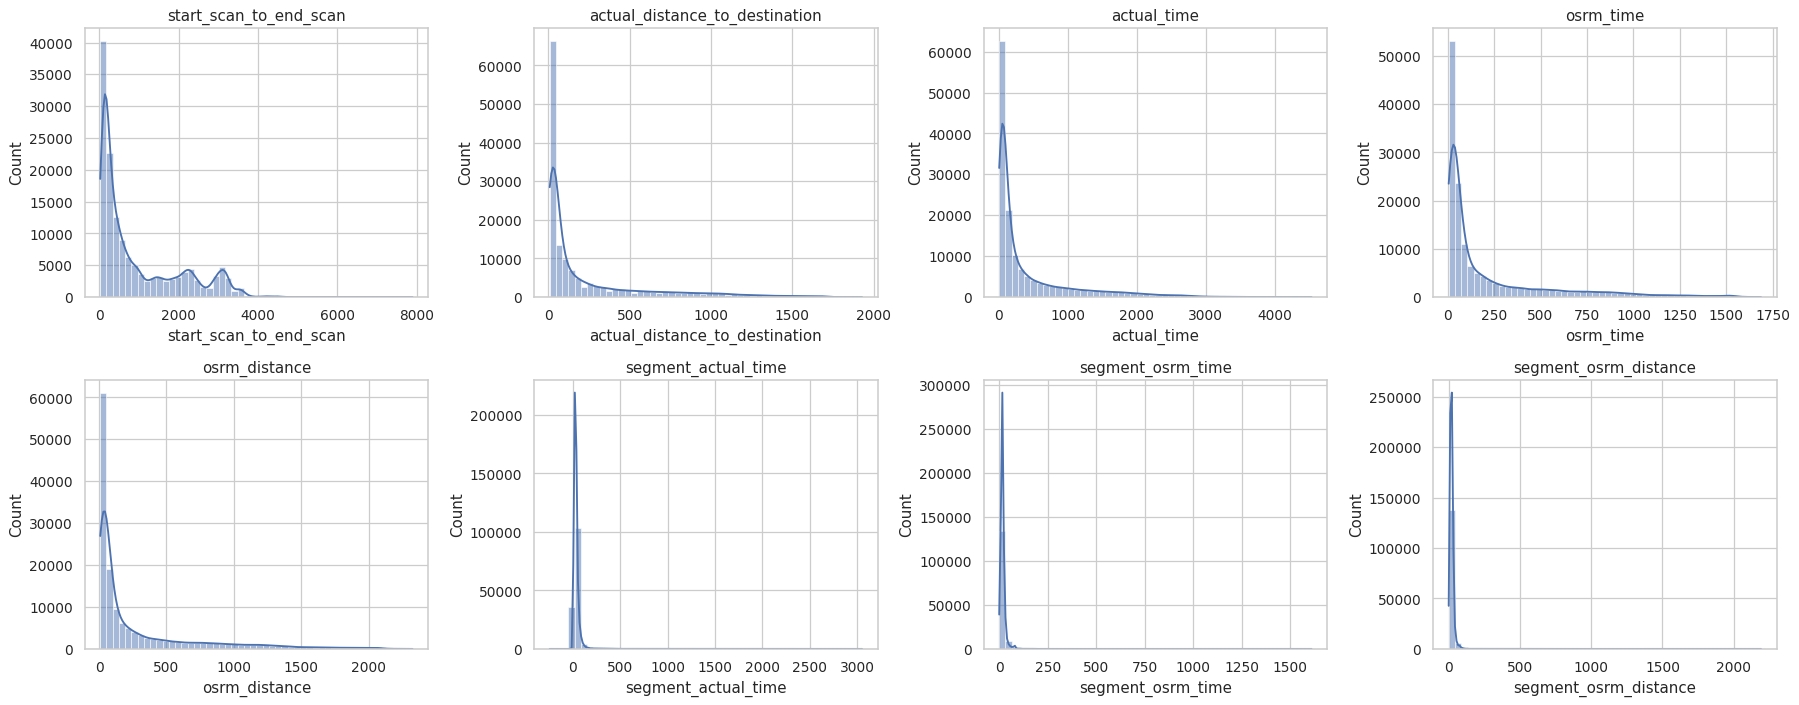

In [6]:
num_cols = ['start_scan_to_end_scan','actual_distance_to_destination','actual_time','osrm_time','osrm_distance',
            'segment_actual_time','segment_osrm_time','segment_osrm_distance']
fig, ax = plt.subplots(2,4, figsize=(20,8))
for a,c in zip(ax.ravel(), num_cols):
    sns.histplot(df[c], bins=50, kde=True, ax=a); a.set_title(c)
plt.tight_layout(); plt.show()

**Comment:** every continuous variable is strongly **right-skewed** (long tail of very long trips); none is normal. Most segments are short (segment time ~ tens of minutes) while a few cumulative values run into thousands of minutes/km. This tells us to expect many IQR outliers and to prefer non-parametric tests.

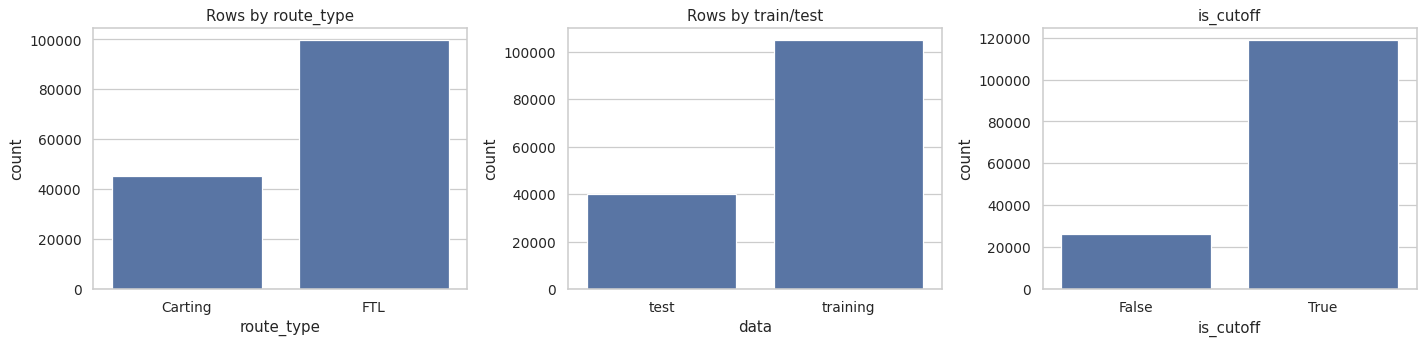

route_type
FTL        0.688
Carting    0.312
Name: proportion, dtype: float64


In [7]:
fig, ax = plt.subplots(1,3, figsize=(16,4))
sns.countplot(x='route_type', data=df, ax=ax[0]); ax[0].set_title('Rows by route_type')
sns.countplot(x='data', data=df, ax=ax[1]); ax[1].set_title('Rows by train/test')
sns.countplot(x='is_cutoff', data=df, ax=ax[2]); ax[2].set_title('is_cutoff')
plt.tight_layout(); plt.show()
print(df.route_type.value_counts(normalize=True).round(3))

**Comment:** FTL rows dominate at segment level (~69% of rows) because FTL trips have more segments each – this reverses when we count *trips* (Carting is the majority, see section 4). Always aggregate before drawing volume conclusions.

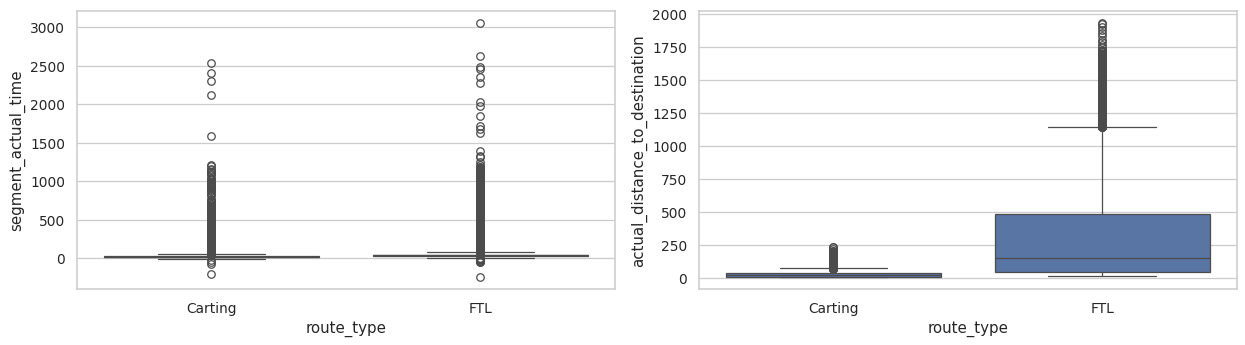

In [8]:
fig, ax = plt.subplots(1,2, figsize=(14,4))
sns.boxplot(x='route_type', y='segment_actual_time', data=df, ax=ax[0])
sns.boxplot(x='route_type', y='actual_distance_to_destination', data=df, ax=ax[1])
plt.tight_layout(); plt.show()

**Comment (bivariate):** FTL segments are longer in both time and distance than Carting; both groups show many high-end outliers.

## 3. Missing values

In [9]:
# Try to recover names via the center-id -> name mapping (an id always maps to one name)
pairs = pd.concat([df[['source_center','source_name']].set_axis(['c','n'],axis=1),
                   df[['destination_center','destination_name']].set_axis(['c','n'],axis=1)]).dropna().drop_duplicates()
print('Centers with >1 name:', (pairs.groupby('c').n.nunique()>1).sum())
cmap = pairs.set_index('c').n.to_dict()
df['source_name'] = df.source_name.fillna(df.source_center.map(cmap))
df['destination_name'] = df.destination_name.fillna(df.destination_center.map(cmap))
print('Still missing -> source:', df.source_name.isna().sum(), '| destination:', df.destination_name.isna().sum())
# these centers never appear with a name in any row: label as Unknown rather than dropping trips
df['source_name'] = df.source_name.fillna('Unknown_Unknown_Unknown (Unknown)')
df['destination_name'] = df.destination_name.fillna('Unknown_Unknown_Unknown (Unknown)')
df.isna().sum().sum()

Centers with >1 name: 0
Still missing -> source: 293 | destination: 261


np.int64(0)

**Approach:** each center id maps to exactly one name, so we first tried to fill gaps from that mapping. It recovered **nothing** – the 293 + 261 missing rows belong to ~10 source and ~13 destination centers that have no name in *any* row. They are therefore labelled `Unknown` instead of dropping the rows (dropping would remove real shipments and bias volume counts; the missing share is only ~0.2%). All other columns have no nulls.

## 4. Merging rows (aggregation)

**How fields behave** (verified on a sample trip): `actual_time`, `osrm_time`, `osrm_distance`, `actual_distance_to_destination` are **cumulative within one source→destination leg** and restart at the next leg. `segment_*` fields are per-row increments.

| Level | Field type | Aggregation |
|---|---|---|
| Leg (trip, source, destination) | cumulative (`actual_time`, `osrm_time`, `osrm_distance`, `actual_distance_to_destination`) | **last** |
| | `segment_*` | **sum** |
| | `start_scan_to_end_scan`, `od_start_time` | first |
| | `od_end_time` | last |
| Trip (trip_uuid) | all numeric leg values | **sum** over legs |
| | source (name/center) / destination | first leg's source / last leg's destination |
| | `od_start_time` / `od_end_time` | first / last |

In [10]:
df = df.sort_values(['trip_uuid','od_start_time'], kind='stable').reset_index(drop=True)
leg = df.groupby(['trip_uuid','source_center','destination_center'], sort=False).agg(
    data=('data','first'), route_type=('route_type','first'), trip_creation_time=('trip_creation_time','first'),
    source_name=('source_name','first'), destination_name=('destination_name','first'),
    od_start_time=('od_start_time','first'), od_end_time=('od_end_time','last'),
    start_scan_to_end_scan=('start_scan_to_end_scan','first'),
    actual_distance_to_destination=('actual_distance_to_destination','last'),
    actual_time=('actual_time','last'), osrm_time=('osrm_time','last'), osrm_distance=('osrm_distance','last'),
    segment_actual_time=('segment_actual_time','sum'), segment_osrm_time=('segment_osrm_time','sum'),
    segment_osrm_distance=('segment_osrm_distance','sum')).reset_index()
print('Leg-level shape:', leg.shape)

num = ['start_scan_to_end_scan','actual_distance_to_destination','actual_time','osrm_time','osrm_distance',
       'segment_actual_time','segment_osrm_time','segment_osrm_distance']
trip = leg.groupby('trip_uuid', sort=False).agg(
    data=('data','first'), route_type=('route_type','first'), trip_creation_time=('trip_creation_time','first'),
    source_center=('source_center','first'), source_name=('source_name','first'),
    destination_center=('destination_center','last'), destination_name=('destination_name','last'),
    od_start_time=('od_start_time','first'), od_end_time=('od_end_time','last'),
    n_legs=('source_center','size'), **{c:(c,'sum') for c in num}).reset_index()
print('Trip-level shape:', trip.shape)
trip.head()

Leg-level shape: (26368, 18)
Trip-level shape: (14817, 19)


,trip_uuid,data,route_type,trip_creation_time,source_center,source_name,destination_center,destination_name,od_start_time,od_end_time,n_legs,start_scan_to_end_scan,actual_distance_to_destination,actual_time,osrm_time,osrm_distance,segment_actual_time,segment_osrm_time,segment_osrm_distance
0,trip-153671041653548748,training,FTL,2018-09-12 00:00:16.535741,IND462022AAA,Bhopal_Trnsport_H (Madhya Pradesh),IND000000ACB,Gurgaon_Bilaspur_HB (Haryana),2018-09-12 00:00:16.535741,2018-09-13 13:40:23.123744,2,2259.0,824.732854,1562.0,717.0,991.3523,1548.0,1008.0,1320.4733
1,trip-153671042288605164,training,Carting,2018-09-12 00:00:22.886430,IND572101AAA,Tumkur_Veersagr_I (Karnataka),IND562101AAA,Chikblapur_ShntiSgr_D (Karnataka),2018-09-12 00:00:22.886430,2018-09-12 03:01:59.598855,2,180.0,73.186911,143.0,68.0,85.1110,141.0,65.0,84.1894
2,trip-153671043369099517,training,FTL,2018-09-12 00:00:33.691250,IND562132AAA,Bangalore_Nelmngla_H (Karnataka),IND160002AAC,Chandigarh_Mehmdpur_H (Punjab),2018-09-12 00:00:33.691250,2018-09-14 17:34:55.442454,2,3933.0,1927.404273,3347.0,1740.0,2354.0665,3308.0,1941.0,2545.2678
3,trip-153671046011330457,training,Carting,2018-09-12 00:01:00.113710,IND400072AAB,Mumbai Hub (Maharashtra),IND401104AAA,Mumbai_MiraRd_IP (Maharashtra),2018-09-12 00:01:00.113710,2018-09-12 01:41:29.809822,1,100.0,17.175274,59.0,15.0,19.6800,59.0,16.0,19.8766
4,trip-153671052974046625,training,FTL,2018-09-12 00:02:09.740725,IND583101AAA,Bellary_Dc (Karnataka),IND583101AAA,Bellary_Dc (Karnataka),2018-09-12 00:02:09.740725,2018-09-12 12:00:30.683231,3,717.0,127.448500,341.0,117.0,146.7918,340.0,115.0,146.7919


**Note:** summing the `segment_*` columns within a leg does not exactly equal the last cumulative value in the raw data (they match exactly in only ~35% of legs for actual time) – a quirk of the source pipeline, which is why we compare them statistically in section 6.

## 5. Feature creation

In [11]:
def split_loc(s):
    state = s.str.extract(r'\((.*)\)')[0]
    parts = s.str.replace(r'\s*\(.*\)', '', regex=True).str.split('_')
    return parts.str[0], parts.str[1], parts.str[2], state

for k in ['source','destination']:
    trip[f'{k}_city'], trip[f'{k}_place'], trip[f'{k}_code'], trip[f'{k}_state'] = split_loc(trip[f'{k}_name'])
    # same city spelled two ways in the data
    trip[f'{k}_city'] = trip[f'{k}_city'].replace({'Bangalore':'Bengaluru'})

t = trip.trip_creation_time
trip['trip_year']=t.dt.year; trip['trip_month']=t.dt.month; trip['trip_day']=t.dt.day
trip['trip_hour']=t.dt.hour; trip['trip_weekday']=t.dt.day_name()

# time between od_start_time and od_end_time (minutes, to match start_scan_to_end_scan)
trip['od_time_diff'] = (trip.od_end_time - trip.od_start_time).dt.total_seconds()/60
trip['corridor_state'] = trip.source_state + ' → ' + trip.destination_state
trip['corridor_city']  = trip.source_city + ' → ' + trip.destination_city
trip[['source_city','source_place','source_code','source_state','destination_city','trip_month','trip_day','trip_weekday','od_time_diff']].head()

,source_city,source_place,source_code,source_state,destination_city,trip_month,trip_day,trip_weekday,od_time_diff
0,Bhopal,Trnsport,H,Madhya Pradesh,Gurgaon,9,12,Wednesday,2260.109800
1,Tumkur,Veersagr,I,Karnataka,Chikblapur,9,12,Wednesday,181.611874
2,Bengaluru,Nelmngla,H,Karnataka,Chandigarh,9,12,Wednesday,3934.362520
3,Mumbai Hub,NaN,NaN,Maharashtra,Mumbai,9,12,Wednesday,100.494935
4,Bellary,Dc,NaN,Karnataka,Bellary,9,12,Wednesday,718.349042


**Notes:** names follow `City_Place_Code (State)`. Some are hubs like `Mumbai Hub (Maharashtra)` with no place/code – those fields are NaN by design. "Bangalore" and "Bengaluru" are the same city, so they were harmonised. All trips are in 2018 (12 Sep – 3 Oct), so `trip_year` is constant and `trip_month` only has 2 values – the time features of most value are `hour`, `weekday` and `day`.

## 6. Comparison & hypothesis tests on aggregated fields

Each pair below is **measured on the same trip**, so we use paired tests. Because the variables are not normal (strong skew, see section 2.1), the **Wilcoxon signed-rank test** is the primary test; the paired t-test is shown for reference. H0: no difference in the two measures. α = 0.05. With ~15k trips even tiny gaps become "significant", so we also report mean gap and correlation (practical size).

In [12]:
pairs = [('od_time_diff','start_scan_to_end_scan'),('actual_time','osrm_time'),('actual_time','segment_actual_time'),
         ('osrm_distance','segment_osrm_distance'),('osrm_time','segment_osrm_time')]
rows=[]
for a,b in pairs:
    w = stats.wilcoxon(trip[a], trip[b]); tt = stats.ttest_rel(trip[a], trip[b])
    rows.append(dict(A=a,B=b,mean_A=trip[a].mean(),mean_B=trip[b].mean(),gap_pct=(trip[a].mean()/trip[b].mean()-1)*100,
                     corr=trip[a].corr(trip[b]),t_pvalue=tt.pvalue,wilcoxon_pvalue=w.pvalue,
                     verdict='Reject H0' if w.pvalue<0.05 else 'Fail to reject'))
res = pd.DataFrame(rows).round(4); res

,A,B,mean_A,mean_B,gap_pct,corr,t_pvalue,wilcoxon_pvalue,verdict
0,od_time_diff,start_scan_to_end_scan,547.4630,530.8100,3.1373,0.9936,0.0,0.0,Reject H0
1,actual_time,osrm_time,357.1438,161.3840,121.3006,0.9586,0.0,0.0,Reject H0
2,actual_time,segment_actual_time,357.1438,353.8923,0.9188,1.0000,0.0,0.0,Reject H0
3,osrm_distance,segment_osrm_distance,204.3447,223.2012,-8.4482,0.9947,0.0,0.0,Reject H0
4,osrm_time,segment_osrm_time,161.3840,180.9498,-10.8128,0.9933,0.0,0.0,Reject H0


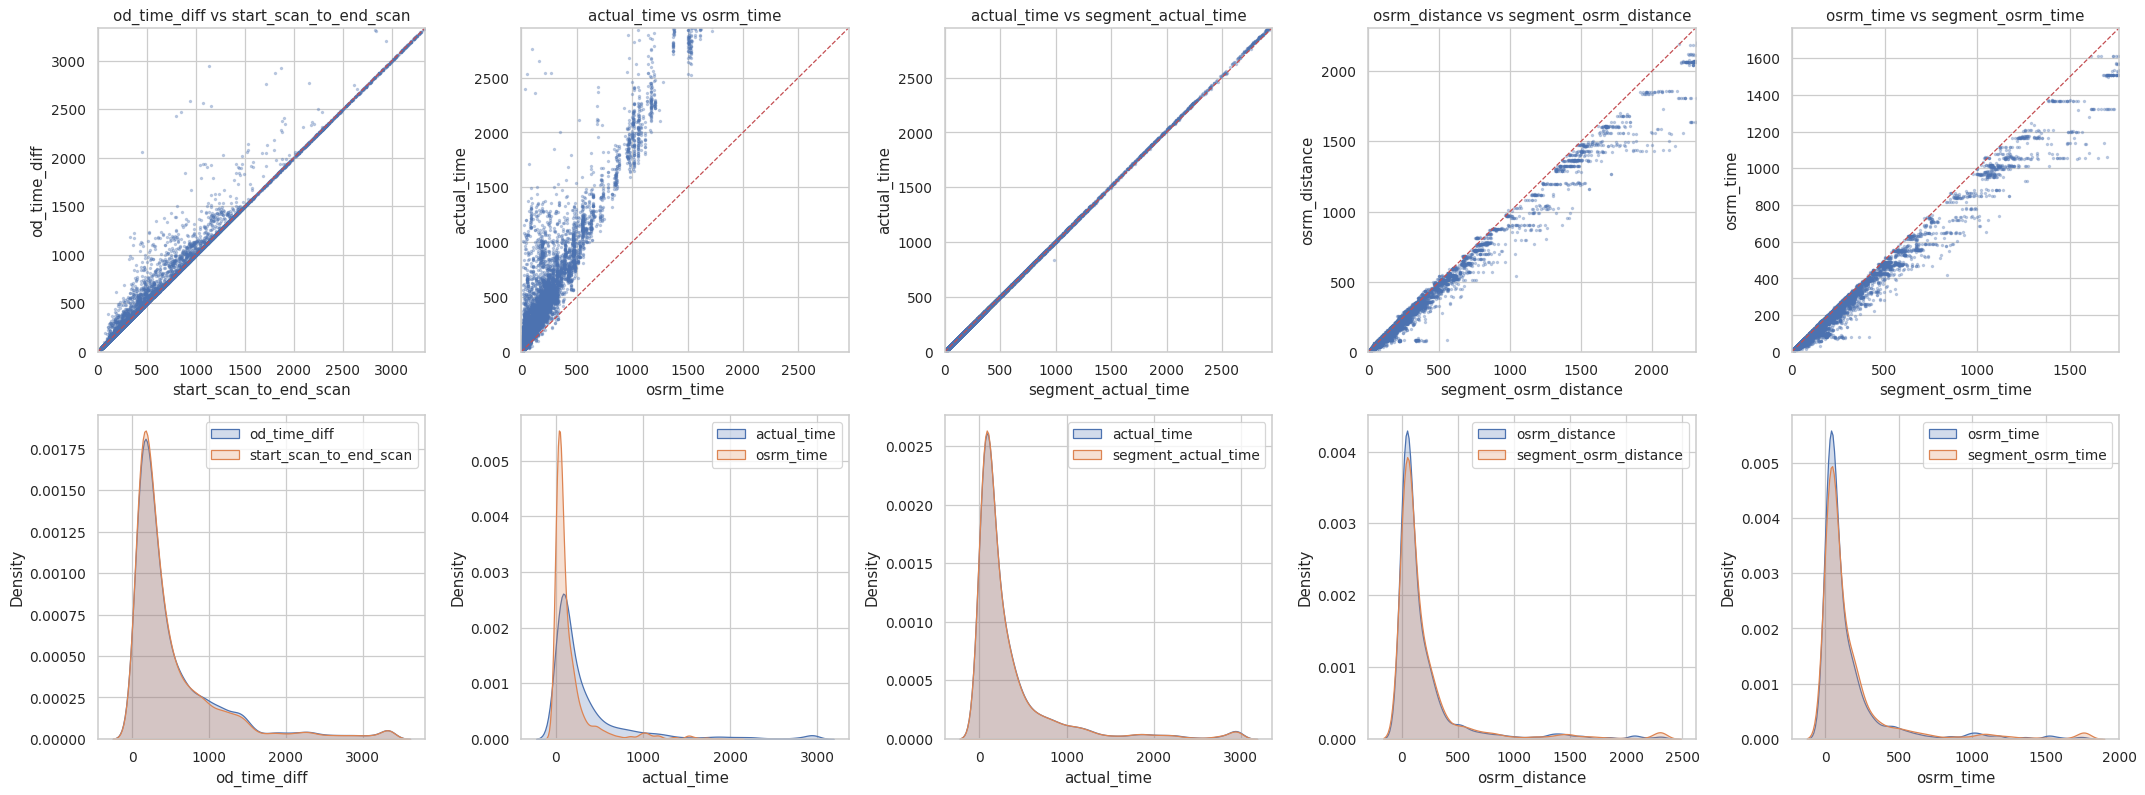

In [13]:
fig, ax = plt.subplots(2,5, figsize=(24,9))
for i,(a,b) in enumerate(pairs):
    lim = trip[[a,b]].quantile(0.99).max()
    ax[0,i].scatter(trip[b], trip[a], s=3, alpha=.3); ax[0,i].plot([0,lim],[0,lim],'r--',lw=1)
    ax[0,i].set_xlim(0,lim); ax[0,i].set_ylim(0,lim); ax[0,i].set_xlabel(b); ax[0,i].set_ylabel(a); ax[0,i].set_title(f'{a} vs {b}')
    sns.kdeplot(trip[a].clip(upper=lim), ax=ax[1,i], label=a, fill=True); sns.kdeplot(trip[b].clip(upper=lim), ax=ax[1,i], label=b, fill=True); ax[1,i].legend()
plt.tight_layout(); plt.show()

**Findings** (red dashed line = perfect agreement)
1. **`od_time_diff` vs `start_scan_to_end_scan`:** very highly correlated (r≈0.99); the timestamp-based duration is only ~3% (~17 min) longer on average. Statistically different (p<0.05) but practically the same measure – scan time can be used interchangeably for modelling.
2. **`actual_time` vs `osrm_time`:** the biggest gap. Real trips take on average **~2.2× (≈+121%)** the OSRM estimate. Still strongly correlated (r≈0.96), so OSRM is a useful *predictor* but needs a correction factor – it systematically under-estimates.
3. **`actual_time` vs `segment_actual_time`:** nearly identical (r≈1.0, gap ≈1%) – segment times add up to the cumulative time, tiny differences only.
4. **`osrm_distance` vs `segment_osrm_distance`** and 5. **`osrm_time` vs `segment_osrm_time`:** correlated at r≈0.99 but segment sums are ~9–12% *higher* than the cumulative figures → differences are statistically significant; the segment version is not a perfect substitute. Prefer the cumulative columns for the model target/features and treat segment sums as a cross-check.

## 7. Outlier detection & treatment

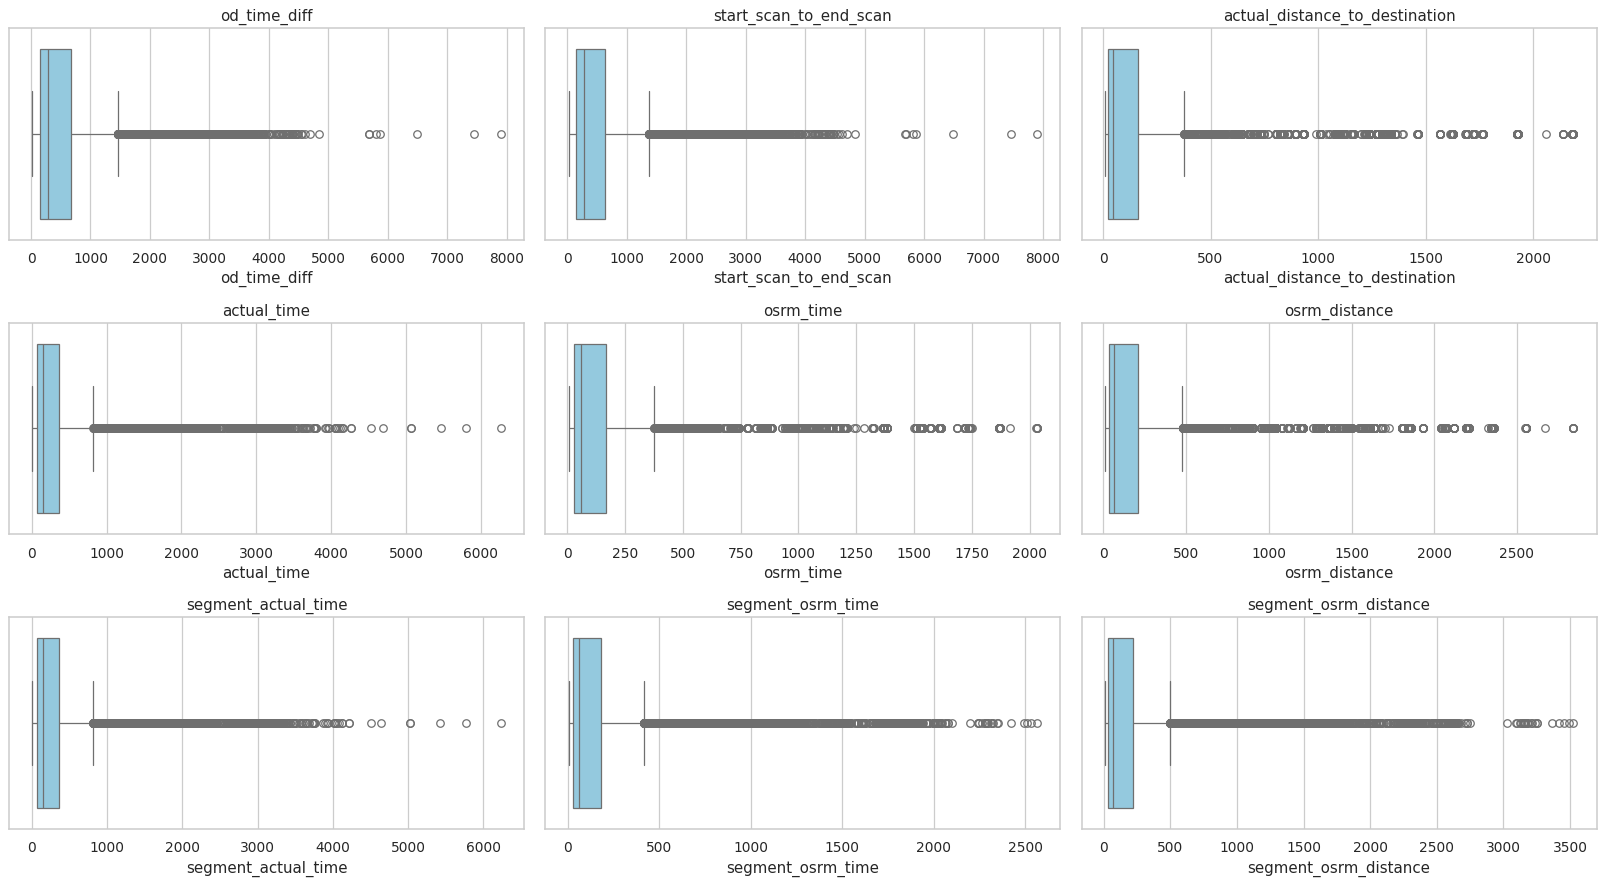

,lower,upper,% outliers
od_time_diff,-632.06,1456.52,7.53
start_scan_to_end_scan,-583.00,1369.00,8.55
actual_distance_to_destination,-189.78,377.20,9.78
actual_time,-387.50,824.50,11.09
osrm_time,-179.50,376.50,10.24
osrm_distance,-235.66,474.96,10.29
segment_actual_time,-385.50,818.50,11.09
segment_osrm_time,-200.00,416.00,10.07
segment_osrm_distance,-246.57,498.02,10.45


In [14]:
out_cols = ['od_time_diff','start_scan_to_end_scan','actual_distance_to_destination','actual_time','osrm_time','osrm_distance',
            'segment_actual_time','segment_osrm_time','segment_osrm_distance']
fig, ax = plt.subplots(3,3, figsize=(18,10))
for a,c in zip(ax.ravel(), out_cols): sns.boxplot(x=trip[c], ax=a, color='skyblue'); a.set_title(c)
plt.tight_layout(); plt.show()
def iqr_bounds(s):
    q1,q3 = s.quantile([.25,.75]); i=q3-q1; return q1-1.5*i, q3+1.5*i
summ = pd.DataFrame({c:{'lower':iqr_bounds(trip[c])[0],'upper':iqr_bounds(trip[c])[1],
        '% outliers':((trip[c]<iqr_bounds(trip[c])[0])|(trip[c]>iqr_bounds(trip[c])[1])).mean()*100} for c in out_cols}).T.round(2)
summ

**Comment:** every numeric variable has a long upper tail with **~8–11% of trips flagged** by the 1.5×IQR rule (there are no lower-side outliers since values are positive and bounded below). These are mostly *genuine* long-haul multi-leg FTL trips rather than errors – so we **cap (winsorise) at the IQR fences instead of deleting rows**, which keeps all 14,817 trips for forecasting while limiting the leverage of extreme values. (Dropping rows would remove ~14% of trips (about 1 in 7) once outliers across columns are combined.)

Rows kept: 14817


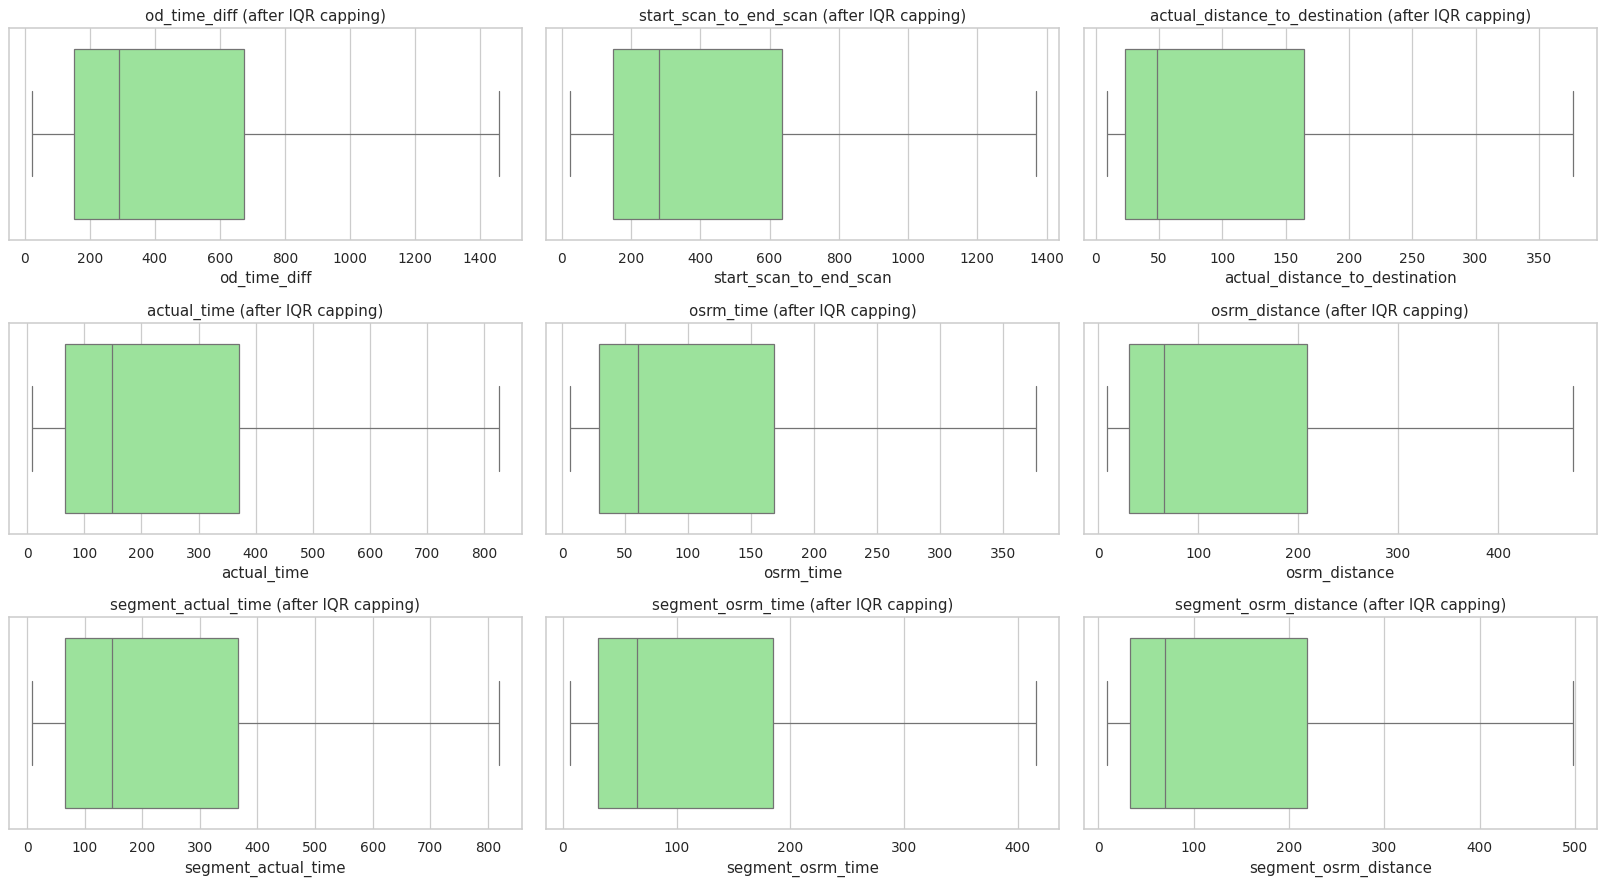

In [15]:
trip_t = trip.copy()
for c in out_cols:
    lo, hi = iqr_bounds(trip[c]); trip_t[c] = trip[c].clip(lo, hi)
print('Rows kept:', len(trip_t))
fig, ax = plt.subplots(3,3, figsize=(18,10))
for a,c in zip(ax.ravel(), out_cols): sns.boxplot(x=trip_t[c], ax=a, color='lightgreen'); a.set_title(c+' (after IQR capping)')
plt.tight_layout(); plt.show()

## 8. Categorical encoding & scaling

In [16]:
# One-hot encode low-cardinality categoricals (route_type, data, weekday). States/cities are high-cardinality: kept as labels for analysis.
enc = pd.get_dummies(trip_t, columns=['route_type','data','trip_weekday'], drop_first=False, dtype=int)
print([c for c in enc.columns if c.startswith(('route_type_','data_','trip_weekday_'))])

scale_cols = out_cols + ['n_legs']
scaler = MinMaxScaler()
model_df = enc.copy()
model_df[scale_cols] = scaler.fit_transform(enc[scale_cols])
model_df[scale_cols].describe().loc[['min','max','mean']].round(3)

['route_type_Carting', 'route_type_FTL', 'data_test', 'data_training', 'trip_weekday_Friday', 'trip_weekday_Monday', 'trip_weekday_Saturday', 'trip_weekday_Sunday', 'trip_weekday_Thursday', 'trip_weekday_Tuesday', 'trip_weekday_Wednesday']


,od_time_diff,start_scan_to_end_scan,actual_distance_to_destination,actual_time,osrm_time,osrm_distance,segment_actual_time,segment_osrm_time,segment_osrm_distance,n_legs
min,0.000,0.00,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
max,1.000,1.00,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
mean,0.315,0.32,0.272,0.313,0.294,0.278,0.312,0.293,0.282,0.111


**Notes:** one-hot encoding turns `route_type` into `route_type_Carting` / `route_type_FTL` (and similarly `data`, weekday). Numeric columns were scaled to 0–1 with **MinMaxScaler** (fit after outlier capping, so scaling is not dominated by extreme values). `StandardScaler` can be swapped in for models that assume a zero-mean input (e.g. linear/regularised models). In a real modelling pipeline fit the scaler on the training split only (`data == 'training'`) to avoid leakage.

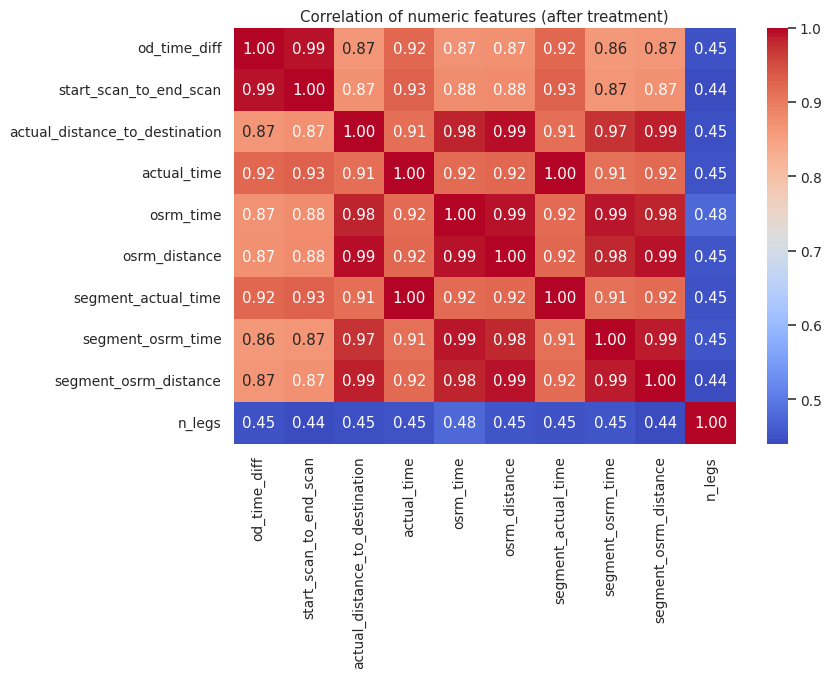

In [17]:
plt.figure(figsize=(9,6))
sns.heatmap(trip_t[out_cols+['n_legs']].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation of numeric features (after treatment)'); plt.show()

**Comment:** distance, OSRM time and actual time are all strongly positively correlated (r > 0.9) → multicollinearity: for linear models keep one of each family (e.g. `osrm_distance` + `osrm_time`) or use regularisation / tree models.

## 9. Business insights

Trips by route type (%):
route_type
Carting    60.1
FTL        39.9
Name: proportion, dtype: float64

            actual_distance_to_destination  actual_time  osrm_time  n_legs
route_type                                                                
Carting                               40.3        125.8       47.4     1.4
FTL                                  351.7        705.9      333.2     2.4


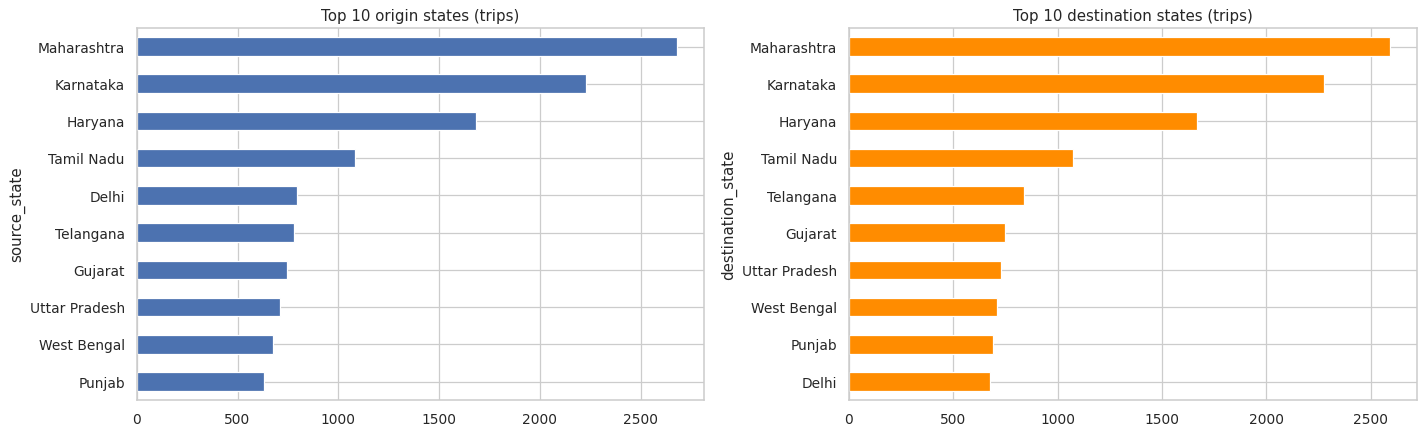

In [18]:
print('Trips by route type (%):'); print((trip.route_type.value_counts(normalize=True)*100).round(1))
print(); print(trip.groupby('route_type')[['actual_distance_to_destination','actual_time','osrm_time','n_legs']].mean().round(1))
fig, ax = plt.subplots(1,2, figsize=(16,5))
trip.source_state.value_counts().head(10).plot.barh(ax=ax[0]).invert_yaxis(); ax[0].set_title('Top 10 origin states (trips)')
trip.destination_state.value_counts().head(10).plot.barh(ax=ax[1], color='darkorange').invert_yaxis(); ax[1].set_title('Top 10 destination states (trips)')
plt.tight_layout(); plt.show()

In [19]:
def corridor_table(col, n=10):
    return (trip.groupby(col).agg(trips=('trip_uuid','size'), avg_distance_km=('actual_distance_to_destination','mean'),
            avg_actual_time_min=('actual_time','mean'), avg_osrm_time_min=('osrm_time','mean'))
            .assign(time_vs_osrm=lambda d: d.avg_actual_time_min/d.avg_osrm_time_min)
            .sort_values('trips', ascending=False).head(n).round(1))
display(corridor_table('corridor_state')); display(corridor_table('corridor_city'))

,trips,avg_distance_km,avg_actual_time_min,avg_osrm_time_min,time_vs_osrm
corridor_state,,,,,
Maharashtra → Maharashtra,2406,60.1,164.0,58.9,2.8
Karnataka → Karnataka,2014,55.2,137.8,65.9,2.1
Tamil Nadu → Tamil Nadu,1016,70.1,153.2,79.5,1.9
Haryana → Haryana,871,122.7,277.4,129.6,2.1
Telangana → Telangana,655,96.0,217.6,94.5,2.3
Gujarat → Gujarat,624,78.2,166.7,80.6,2.1
West Bengal → West Bengal,610,79.3,289.3,89.3,3.2
Uttar Pradesh → Uttar Pradesh,541,99.0,335.2,110.3,3.0
Punjab → Punjab,491,141.8,308.7,141.3,2.2


,trips,avg_distance_km,avg_actual_time_min,avg_osrm_time_min,time_vs_osrm
corridor_city,,,,,
Bengaluru → Bengaluru,1376,37.2,99.5,49.8,2.0
Hyderabad → Hyderabad,398,85.9,200.9,80.4,2.5
Bhiwandi → Mumbai,332,23.0,78.4,25.9,3.0
Mumbai → Mumbai,264,16.2,69.1,19.1,3.6
Chandigarh → Chandigarh,250,170.3,392.6,175.0,2.2
Gurgaon → Delhi,240,48.7,126.5,59.5,2.1
Mumbai Hub → Mumbai,227,16.3,56.9,18.1,3.1
Mumbai → Bhiwandi,207,21.6,94.5,24.9,3.8
Chennai → Chennai,201,29.8,77.6,30.8,2.5


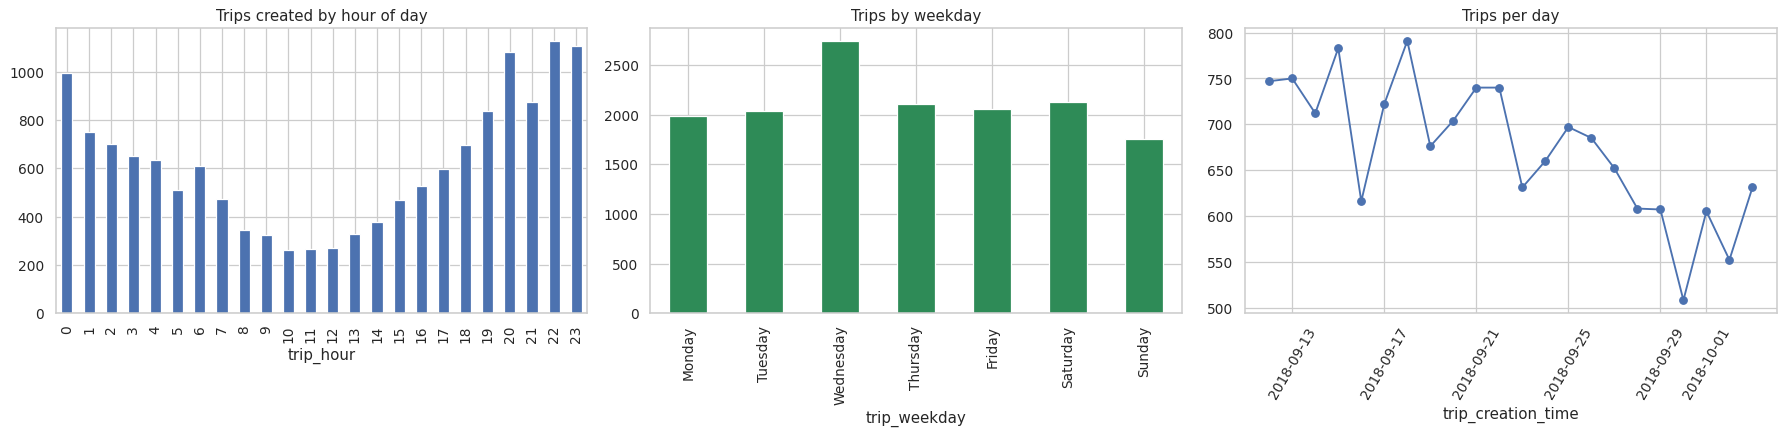

In [20]:
fig, ax = plt.subplots(1,3, figsize=(20,5))
trip.groupby('trip_hour').size().plot.bar(ax=ax[0]); ax[0].set_title('Trips created by hour of day')
trip.groupby('trip_weekday').size().reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']).plot.bar(ax=ax[1], color='seagreen'); ax[1].set_title('Trips by weekday')
trip.groupby(trip.trip_creation_time.dt.date).size().plot(ax=ax[2], marker='o'); ax[2].set_title('Trips per day'); ax[2].tick_params(axis='x', rotation=60)
plt.tight_layout(); plt.show()

In [21]:
trip['time_ratio'] = trip.actual_time/trip.osrm_time
st = (trip.groupby('source_state').agg(trips=('trip_uuid','size'), median_ratio=('time_ratio','median')).query('trips>=100').sort_values('median_ratio', ascending=False))
st.round(2).head(8)

,trips,median_ratio
source_state,,
Bihar,357,2.92
West Bengal,677,2.73
Assam,273,2.55
Uttar Pradesh,713,2.45
Maharashtra,2682,2.42
Jharkhand,160,2.40
Orissa,107,2.27
Madhya Pradesh,332,2.20


### Key insights
1. **Volume is concentrated in a handful of states.** Maharashtra, Karnataka and Haryana are the top origin *and* destination states, followed by Tamil Nadu, Telangana, Gujarat and Uttar Pradesh.
2. **Most traffic is local.** The busiest state corridors are all *within the same state* (Maharashtra→Maharashtra ≈2,400 trips, Karnataka→Karnataka ≈2,000, Tamil Nadu, Haryana, Telangana…). Typical distance ≈55–150 km, ≈2–5.5 h. Maharashtra→Maharashtra runs at ~2.8× its OSRM time.
3. **Busiest city corridors:** Bengaluru→Bengaluru (≈1,376 trips after harmonising the Bangalore/Bengaluru spelling; avg ≈37 km, ≈1.7 h), Hyderabad→Hyderabad (≈400; ≈86 km, ≈3.3 h), Bhiwandi→Mumbai (≈330; ≈23 km, ≈1.3 h), Chandigarh→Chandigarh (≈250; ≈170 km, ≈6.5 h) and Gurgaon→Delhi (≈240; ≈49 km, ≈2.1 h).
4. **Carting = 60% of trips (short, ~40 km, ~2 h, 1.4 legs); FTL = 40% (long, ~350 km, ~12 h, 2.4 legs).** FTL trips are fewer but carry most of the distance/time.
5. **Real trips are ~2× slower than OSRM.** Actual time averages 2.2× OSRM time (median ratio ≈2.1 – ≈2.0 for FTL, ≈2.2 for Carting). Among states with 100+ trips, Bihar (≈2.9×), West Bengal (≈2.7×) and Assam (≈2.6×) are the slowest relative to plan; very small-volume hill/remote states (Mizoram, Himachal, Nagaland, J&K) run 3.5–5× OSRM. Short Mumbai–Bhiwandi runs are ≈3–3.8× OSRM.
6. **Demand is evening/night heavy.** Trip creation peaks between roughly 8 pm and midnight; Wednesday is the busiest weekday, Sunday the quietest.
7. **Data-quality flags:** duplicate city spellings (Bangalore/Bengaluru), ~10 source / ~13 destination centres with no name anywhere, and segment sums that don't exactly equal cumulative figures.

## 10. Recommendations (simple, non-technical)
1. **Plan with a realistic clock.** Customer ETAs built on map estimates are about half of what really happens. Use a "real-world" factor (about 2× for typical routes, higher for hill/remote states) when promising delivery times.
2. **Add capacity where the volume is** – Maharashtra, Karnataka and Haryana, especially the Bengaluru, Mumbai/Bhiwandi, Hyderabad and Gurgaon–Delhi corridors. Short local runs dominate, so more small vehicles (Carting) in these cities pays off.
3. **Staff and schedule for the evening rush** (8 pm – midnight) and for Wednesdays; use Sundays for maintenance and training.
4. **Investigate the slowest routes** (Bihar, West Bengal, Assam, the Mumbai–Bhiwandi runs and hill/remote states) – find out where time is lost (loading waits, road conditions, detours) and fix the top causes.
5. **Fix the basics in the data:** one official name per city/centre, fill in missing centre names, and make segment totals match trip totals. Cleaner data = better forecasts.
6. **Review FTL vs Carting mix:** FTL trips drive most distance and time; track on-time performance for them separately.